In [27]:
# Part 2

In [28]:
# 2.1 First look

from google.colab import drive
drive.mount("/content/drive")

!pip -q install astroNN

from pathlib import Path
import numpy as np

folder = Path("/content/drive/MyDrive/PHYS2550_HW2")
folder.mkdir(parents=True, exist_ok=True)

data_path = folder / "galaxy10_sdss.npz"

if data_path.exists():
    with np.load(data_path) as data:
        images = data["images"]
        labels = data["labels"]
    print("Loaded data from Google Drive.")
else:
    from astroNN.datasets import load_galaxy10sdss

    images, labels = load_galaxy10sdss()
    np.savez_compressed(data_path, images=images, labels=labels)
    print("Downloaded and saved data to Google Drive.")

labels = np.asarray(labels).reshape(-1)

print("Image array shape:", images.shape)
print("Label array shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)
print("Pixel range:", images.min(), "to", images.max())

assert len(images) == len(labels)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded data from Google Drive.
Image array shape: (21785, 69, 69, 3)
Label array shape: (21785,)
Image data type: uint8
Label data type: uint8
Pixel range: 0 to 255


The Galaxy10 SDSS dataset contains 21,785 galaxy images. The image array has shape (21785, 69, 69, 3), corresponding to 69 × 69 pixels and three colour channels per image. The label array has shape (21785,). Both arrays use the uint8 data type, and pixel values range from 0 to 255.

,Class,Morphology,Count,Percentage (%)
0,0,"Disk, face-on, no spiral",3461,15.89
1,1,"Smooth, completely round",6997,32.12
2,2,"Smooth, in-between round",6292,28.88
3,3,"Smooth, cigar shaped",349,1.60
4,4,"Disk, edge-on, rounded bulge",1534,7.04
5,5,"Disk, edge-on, boxy bulge",17,0.08
6,6,"Disk, edge-on, no bulge",589,2.70
7,7,"Disk, face-on, tight spiral",1121,5.15
8,8,"Disk, face-on, medium spiral",906,4.16
9,9,"Disk, face-on, loose spiral",519,2.38


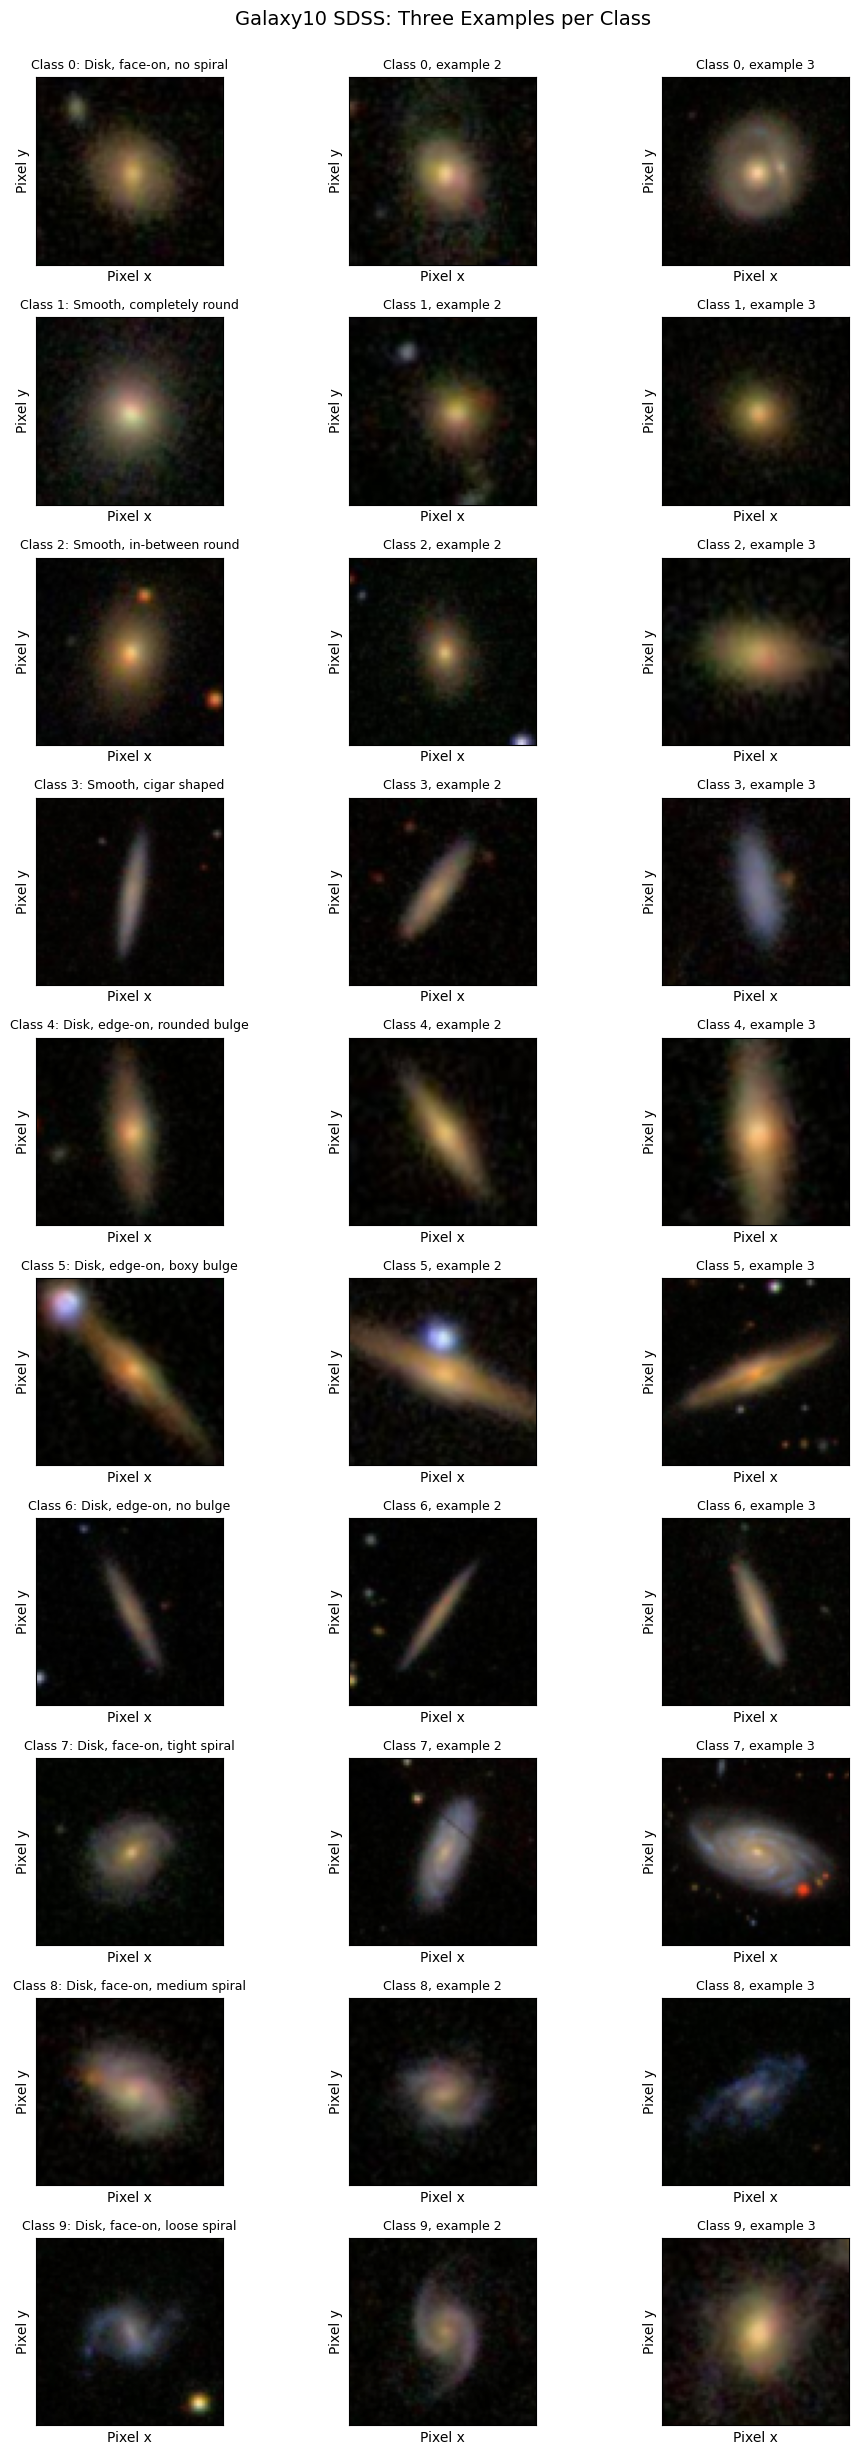

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

class_names = [
    "Disk, face-on, no spiral",
    "Smooth, completely round",
    "Smooth, in-between round",
    "Smooth, cigar shaped",
    "Disk, edge-on, rounded bulge",
    "Disk, edge-on, boxy bulge",
    "Disk, edge-on, no bulge",
    "Disk, face-on, tight spiral",
    "Disk, face-on, medium spiral",
    "Disk, face-on, loose spiral"
]

counts = np.bincount(labels.astype(int), minlength=10)

class_table = pd.DataFrame({
    "Class": np.arange(10),
    "Morphology": class_names,
    "Count": counts,
    "Percentage (%)": np.round(100 * counts / len(labels), 2)
})

display(class_table)
class_table.to_csv(folder / "class_counts.csv", index=False)

# Use a fixed seed to make the example selection reproducible.
rng = np.random.default_rng(42)

fig, axes = plt.subplots(10, 3, figsize=(10, 25))

for c in range(10):
    indices = np.flatnonzero(labels == c)
    selected = rng.choice(indices, size=3, replace=False)

    for j, idx in enumerate(selected):
        ax = axes[c, j]
        ax.imshow(images[idx])
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("Pixel x")
        ax.set_ylabel("Pixel y")

        if j == 0:
            ax.set_title(f"Class {c}: {class_names[c]}", fontsize=9)
        else:
            ax.set_title(f"Class {c}, example {j + 1}", fontsize=9)

fig.suptitle("Galaxy10 SDSS: Three Examples per Class", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(folder / "class_examples.png", dpi=200, bbox_inches="tight")
plt.show()

The class distribution is highly imbalanced. Classes 1 and 2 together account for approximately 61% of the dataset, whereas class 5 contains only 17 images (0.08%). Classes 3, 9, and 6 are also relatively rare. I retain all ten classes to preserve the original classification task and the reference architectures. However, performance estimates for class 5 will be highly uncertain because it contributes very few validation and test examples. Balanced accuracy will therefore be reported alongside overall accuracy.
The dataset is split into approximately 70% training, 15% validation, and 15% test data using stratified sampling with a fixed random seed of 42. The split indices are saved and reused for every experiment. The test set is reserved for the final evaluations in Part 3.

In [30]:
from sklearn.model_selection import train_test_split

SEED = 42
indices = np.arange(len(labels))

# split into 70% training and 30% temporary data.
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# split the remaining 30% equally into validation and test sets.
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx]
)

# verify that the sets are disjoint and cover the full dataset.
assert len(np.intersect1d(train_idx, val_idx)) == 0
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(np.intersect1d(val_idx, test_idx)) == 0
assert len(train_idx) + len(val_idx) + len(test_idx) == len(labels)

# save the exact split for all later experiments.
np.savez(
    folder / "split_indices.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

split_table = pd.DataFrame({
    "Class": np.arange(10),
    "Train": np.bincount(labels[train_idx], minlength=10),
    "Validation": np.bincount(labels[val_idx], minlength=10),
    "Test": np.bincount(labels[test_idx], minlength=10)
})

print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Test images:", len(test_idx))
print()
print(split_table.to_string(index=False))

split_table.to_csv(folder / "split_counts.csv", index=False)

Training images: 15249
Validation images: 3268
Test images: 3268

 Class  Train  Validation  Test
     0   2423         519   519
     1   4898        1049  1050
     2   4404         944   944
     3    244          53    52
     4   1074         230   230
     5     12           2     3
     6    412          89    88
     7    785         168   168
     8    634         136   136
     9    363          78    78


The stratified split produces 15,249 training images, 3,268 validation images, and 3,268 test images. Class 5 contributes only 12 training, 2 validation, and 3 test examples, so its measured recall will be highly uncertain.

Border pixels per image: 1040
Background array shape: (15249, 3)
Noise array shape: (15249, 3)
  Channel  Median background  Median std noise  Median MAD noise  Zero MAD fraction
Channel 0                6.0          5.918722            4.4478           0.000262
Channel 1                6.0          5.159757            2.9652           0.000328
Channel 2                3.0          4.478724            2.9652           0.000393


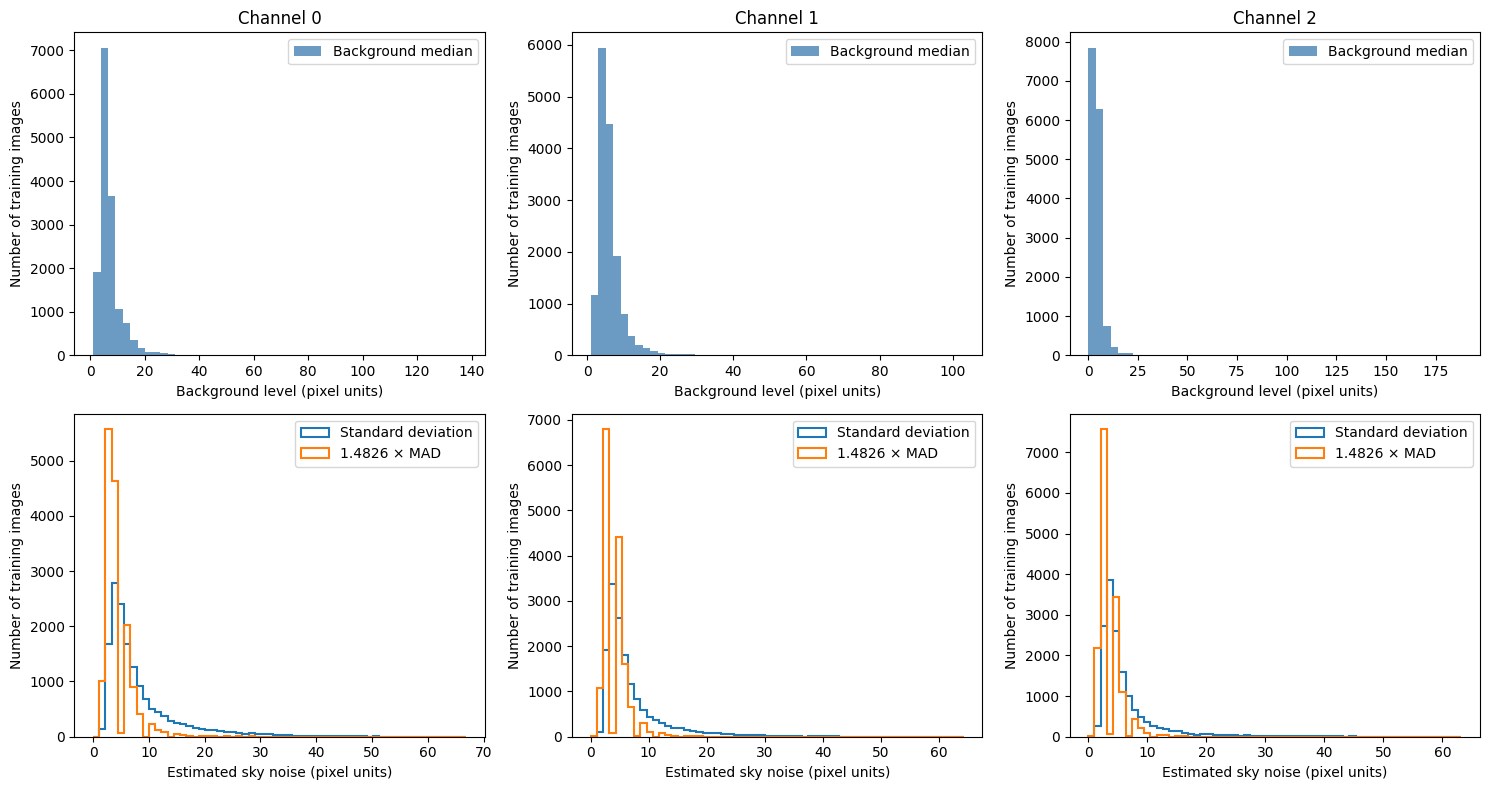

In [31]:
# 2.2（a）

# use training images only
train_images = images[train_idx]
train_labels = labels[train_idx]

# outer 4-pixel frame, without counting corners twice
border_mask = np.ones((69, 69), dtype=bool)
border_mask[4:-4, 4:-4] = False

# shape: (number of training images, border pixels, channels)
border_pixels = train_images[:, border_mask, :].astype(np.float32)

sky_median = np.median(border_pixels, axis=1)
sky_std = np.std(border_pixels, axis=1)

mad = np.median(
    np.abs(border_pixels - sky_median[:, None, :]),
    axis=1
)
sky_mad = 1.4826 * mad

print("Border pixels per image:", border_mask.sum())
print("Background array shape:", sky_median.shape)
print("Noise array shape:", sky_std.shape)

# keep neutral channel names until the stored band order is confirmed
band_names = ["Channel 0", "Channel 1", "Channel 2"]

noise_summary = pd.DataFrame({
    "Channel": band_names,
    "Median background": np.median(sky_median, axis=0),
    "Median std noise": np.median(sky_std, axis=0),
    "Median MAD noise": np.median(sky_mad, axis=0),
    "Zero MAD fraction": np.mean(sky_mad == 0, axis=0)
})

print(noise_summary.to_string(index=False))

noise_summary.to_csv(folder / "sky_noise_summary.csv", index=False)

np.savez(
    folder / "training_sky_estimates.npz",
    train_idx=train_idx,
    sky_median=sky_median,
    sky_std=sky_std,
    sky_mad=sky_mad
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for c, name in enumerate(band_names):
    axes[0, c].hist(
        sky_median[:, c],
        bins=50,
        label="Background median",
        color="steelblue",
        alpha=0.8
    )
    axes[0, c].set_title(name)
    axes[0, c].set_xlabel("Background level (pixel units)")
    axes[0, c].set_ylabel("Number of training images")
    axes[0, c].legend()

    # Use identical bin edges for both noise estimators.
    bins = np.histogram_bin_edges(
        np.concatenate([sky_std[:, c], sky_mad[:, c]]),
        bins=60
    )

    axes[1, c].hist(
        sky_std[:, c],
        bins=bins,
        histtype="step",
        linewidth=1.5,
        label="Standard deviation"
    )
    axes[1, c].hist(
        sky_mad[:, c],
        bins=bins,
        histtype="step",
        linewidth=1.5,
        label="1.4826 × MAD"
    )
    axes[1, c].set_xlabel("Estimated sky noise (pixel units)")
    axes[1, c].set_ylabel("Number of training images")
    axes[1, c].legend()

plt.tight_layout()
plt.savefig(folder / "sky_noise_distributions.png",
            dpi=200, bbox_inches="tight")
plt.show()

For each training image and each channel, I use the outer four-pixel frame, containing 1,040 pixels, to estimate the sky background and noise. The background is estimated by the median. The noise is estimated using both the standard deviation and the robust estimator 1.4826 times MAD. The standard deviation is sensitive to bright neighbouring sources, extended galaxy light, and other outliers in the border. The MAD estimator is less sensitive to such contamination. The estimators may also disagree because the background is not Gaussian or because 8-bit quantisation affects the pixel distribution. The factor 1.4826 makes MAD consistent with the standard deviation for Gaussian noise.

Aperture pixels: 197
Images excluded for zero noise: 0
 Class  Valid images  Median aperture flux  Median SNR
     0          2423               62405.0  779.838183
     1          4898               64376.0  626.657574
     2          4404               71134.5  655.434935
     3           244               61494.0  745.898402
     4          1074               57230.0  698.794022
     5            12               54160.0  751.378910
     6           412               38744.0  667.053663
     7           785               64290.0  953.660943
     8           634               61544.0  852.605971
     9           363               57644.0  701.417383


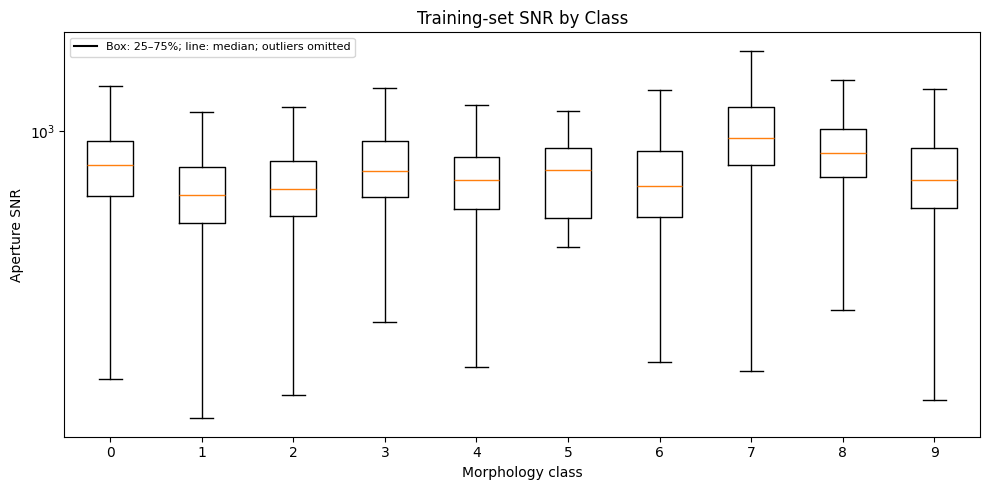

In [32]:
# 2.2（b）

# circular aperture: radius 8 pixels, centred on the image
yy, xx = np.indices((69, 69))
aperture_mask = (xx - 34)**2 + (yy - 34)**2 <= 8**2
n_aperture = aperture_mask.sum()

# background-subtracted aperture flux, separately for each channel
aperture_pixels = train_images[:, aperture_mask, :].astype(np.float32)

flux_per_band = (
    aperture_pixels.sum(axis=1)
    - n_aperture * sky_median
)

# use MAD; fall back to standard deviation where MAD is zero
noise_used = np.where(sky_mad > 0, sky_mad, sky_std)

total_flux = flux_per_band.sum(axis=1)
noise_aperture = np.sqrt(
    n_aperture * np.sum(noise_used**2, axis=1)
)

valid = np.all(noise_used > 0, axis=1)

snr = np.full(len(train_images), np.nan)
snr[valid] = total_flux[valid] / noise_aperture[valid]

# Save both SNR and flux: lower SNR does not necessarily mean lower flux
snr_table = pd.DataFrame({
    "Class": np.arange(10),
    "Valid images": [
        np.sum(valid & (train_labels == c)) for c in range(10)
    ],
    "Median aperture flux": [
        np.nanmedian(total_flux[train_labels == c]) for c in range(10)
    ],
    "Median SNR": [
        np.nanmedian(snr[train_labels == c]) for c in range(10)
    ]
})

print("Aperture pixels:", n_aperture)
print("Images excluded for zero noise:", np.sum(~valid))
print(snr_table.to_string(index=False))

snr_table.to_csv(folder / "snr_by_class.csv", index=False)
np.savez(
    folder / "training_snr.npz",
    train_idx=train_idx,
    snr=snr,
    total_flux=total_flux,
    flux_per_band=flux_per_band
)

# show each class distribution without hiding rare classes
snr_groups = [
    snr[(train_labels == c) & valid] for c in range(10)
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(snr_groups, showfliers=False)
ax.set_xticks(np.arange(1, 11))
ax.set_xticklabels(np.arange(10))
ax.set_xlabel("Morphology class")
ax.set_ylabel("Aperture SNR")
ax.set_title("Training-set SNR by Class")
ax.plot([], [], color="black",
        label="Box: 25–75%; line: median; outliers omitted")
ax.legend(fontsize=8)

# preserve possible negative values while displaying a wide range
ax.set_yscale("symlog", linthresh=10)

plt.tight_layout()
plt.savefig(folder / "snr_by_class.png",
            dpi=200, bbox_inches="tight")
plt.show()


For an aperture A of radius eight pixels, containing N_pix = 197 pixels, the total background-subtracted flux is F = Σ(c=0 to 2) Σ(p∈A) [I(p,c) − b_c]. Assuming independent noise between pixels and channels, the aperture noise and SNR are σ_aperture = √[N_pix × (σ_0² + σ_1² + σ_2²)], SNR = F / σ_aperture. Here, b_c is the border median in channel c, and σ_c is 1.4826 × MAD, with the border standard deviation used when MAD is zero.

The aperture contains 197 pixels, and no training images are excluded for zero noise. Class 6 has the lowest median background-subtracted aperture flux (38,744 pixel units), whereas class 1 has the lowest median SNR (626.7). Class 7 has the highest median SNR (953.7). Thus, lower aperture flux does not necessarily imply lower SNR. Class 5 has only 12 training examples, making its summary statistics uncertain.
These SNR values describe the stored 8-bit images under an independent-noise approximation. They do not include source shot noise or pixel correlations, and a high aperture SNR does not guarantee that faint morphological features are clearly resolved.

Candidate border contamination: 73.05%
Saturated channel values: 0.000517%
Images with any saturation: 2.29%
Channel 0 saturated values: 0.000707%
Channel 1 saturated values: 0.000095%
Channel 2 saturated values: 0.000751%


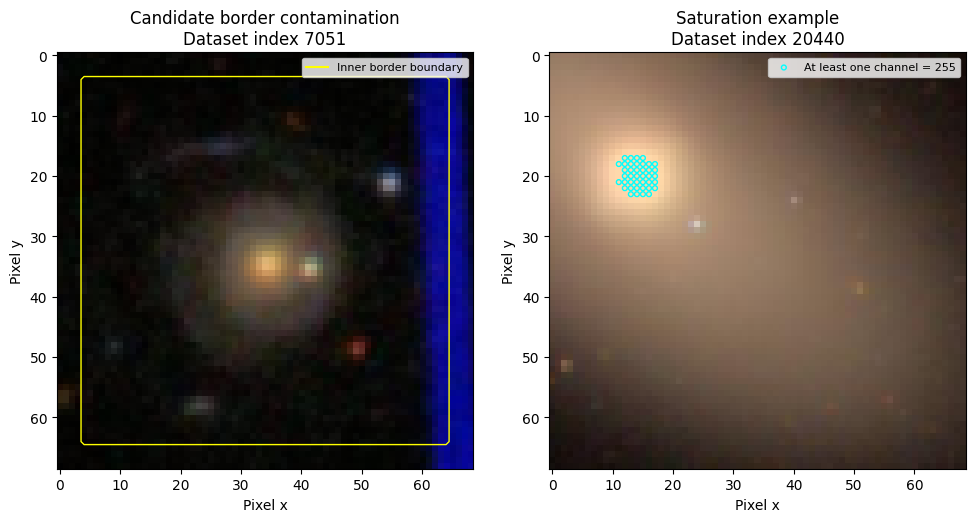

In [33]:
# 2.2（c）

from scipy.ndimage import label, find_objects

contaminated = np.zeros(len(train_images), dtype=bool)
largest_border_group = np.zeros(len(train_images), dtype=int)

for i in range(len(train_images)):
    # detect pixels exceeding the background by 5 sigma in any channel
    threshold = sky_median[i] + 5 * noise_used[i]

    bright = np.any(
        train_images[i].astype(np.float32) > threshold,
        axis=2
    )
    bright &= border_mask

    # eight-connected groups within the border
    groups, n_groups = label(
        bright, structure=np.ones((3, 3), dtype=int)
    )

    sizes = np.bincount(groups.ravel())[1:]
    largest = sizes.max() if sizes.size else 0

    largest_border_group[i] = largest
    contaminated[i] = largest >= 3

# fraction of individual channel values equal to 255
sat_counts = np.count_nonzero(
    train_images == 255, axis=(1, 2, 3)
)
saturated_images = sat_counts > 0

sat_fraction = sat_counts.sum() / train_images.size
sat_per_band = np.mean(train_images == 255, axis=(0, 1, 2))

print(f"Candidate border contamination: {100 * contaminated.mean():.2f}%")
print(f"Saturated channel values: {100 * sat_fraction:.6f}%")
print(f"Images with any saturation: {100 * saturated_images.mean():.2f}%")

for c in range(3):
    print(f"Channel {c} saturated values: {100 * sat_per_band[c]:.6f}%")

# display one candidate contamination example and one saturation example.
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

candidate_ids = np.flatnonzero(contaminated)
saturated_ids = np.flatnonzero(saturated_images)

if len(candidate_ids):
    # A reproducible example: strongest connected border detection
    i = candidate_ids[
        np.argmax(largest_border_group[candidate_ids])
    ]
    axes[0].imshow(train_images[i])
    axes[0].contour(
        border_mask.astype(float),
        levels=[0.5], colors="yellow", linewidths=1
    )
    axes[0].set_title(
        f"Candidate border contamination\nDataset index {train_idx[i]}"
    )
    axes[0].plot([], [], color="yellow", label="Inner border boundary")
    axes[0].legend(fontsize=8)
else:
    axes[0].set_title("No candidate contamination detected")

if len(saturated_ids):
    i = saturated_ids[np.argmax(sat_counts[saturated_ids])]
    axes[1].imshow(train_images[i])
    y_sat, x_sat = np.where(np.any(train_images[i] == 255, axis=2))
    axes[1].scatter(
        x_sat, y_sat, s=12, facecolors="none",
        edgecolors="cyan", label="At least one channel = 255"
    )
    axes[1].set_title(
        f"Saturation example\nDataset index {train_idx[i]}"
    )
    axes[1].legend(fontsize=8)
else:
    axes[1].set_title("No saturated pixels detected")

for ax in axes:
    ax.set_xlabel("Pixel x")
    ax.set_ylabel("Pixel y")

plt.tight_layout()
plt.savefig(folder / "contamination_saturation_examples.png",
            dpi=200, bbox_inches="tight")
plt.show()



Using a screening criterion of at least three connected border pixels exceeding the estimated background by 5 sigma in any channel, 73.05% of training images are flagged. This is a candidate bright-border fraction, not a confirmed neighbouring-source fraction: extended galaxy light, correlated pixels, and underestimated background noise can also trigger the criterion.
Only 0.000517% of channel values equal 255, although 2.29% of images contain at least one such value. Border contamination can obscure faint galaxy emission and bias background estimates. Values at the upper limit may indicate clipping, which removes information about peak intensity and potentially central structure; quantisation also removes intensity differences smaller than one stored level.

In [34]:
# 2.2（d）

Classes 1 and 2 may be confused because the distinction between completely round and intermediate-round galaxies is gradual. Classes 0 and 7 may be confused when tightly wound spiral arms are faint or unresolved. Classes 7, 8, and 9 differ by spiral-arm winding, which can be difficult to judge. Classes 4, 5, and 6 may also be confused when the bulge is poorly resolved.
Because the labels are derived from volunteer votes, similar images may receive inconsistent labels. Such ambiguity creates irreducible uncertainty when predicting the assigned labels and can prevent perfect generalisation. The numerical accuracy ceiling cannot be determined from these hard labels alone.

The dataset contains background fluctuations, possible neighbouring-source contamination, quantisation, occasional values at the upper intensity limit, and uncertain morphology labels. Background subtraction and suitable denoising or masking can reduce some image-level effects, but cannot recover information lost through quantisation or clipping. Label errors require improved annotations or probabilistic vote information. A high central-aperture SNR does not eliminate uncertainty in faint morphological features.

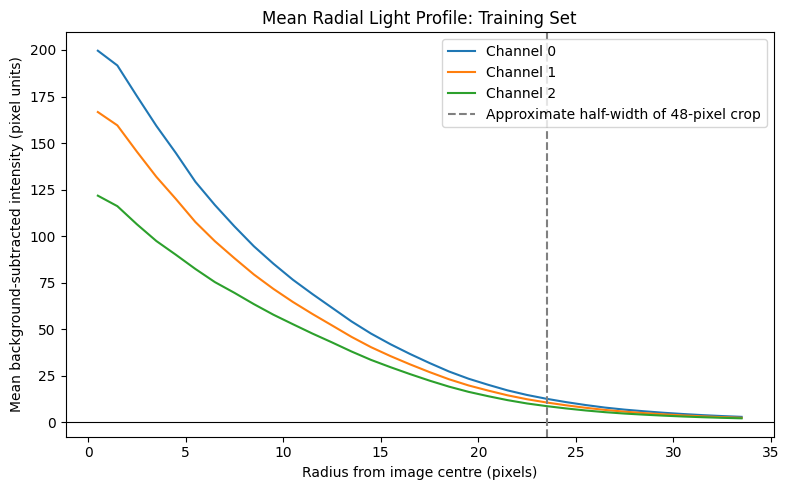

  Channel  Central mean (r < 3)  Mean near r = 24  Boundary / central
Channel 0            188.842450         11.730720            0.062119
Channel 1            157.183712          9.881446            0.062866
Channel 2            114.737856          8.065986            0.070299


In [35]:
# 2.3（a）

# Distance from the centre of the original 69 × 69 image.
yy, xx = np.indices((69, 69))
radius = np.sqrt((xx - 34)**2 + (yy - 34)**2)
radial_bin = np.floor(radius).astype(int)

# Use complete circular annuli within the image.
r_values = np.arange(34)
radial_profile = np.zeros((len(r_values), 3))

for r in r_values:
    mask = radial_bin == r

    # Mean within the annulus for each image and channel,
    # then subtract that image's estimated background.
    annulus_mean = train_images[:, mask, :].mean(axis=1)
    radial_profile[r] = (annulus_mean - sky_median).mean(axis=0)

fig, ax = plt.subplots(figsize=(8, 5))

for c, name in enumerate(band_names):
    ax.plot(r_values + 0.5, radial_profile[:, c], label=name)

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(
    23.5, color="gray", linestyle="--",
    label="Approximate half-width of 48-pixel crop"
)
ax.set_xlabel("Radius from image centre (pixels)")
ax.set_ylabel("Mean background-subtracted intensity (pixel units)")
ax.set_title("Mean Radial Light Profile: Training Set")
ax.legend()

plt.tight_layout()
plt.savefig(folder / "radial_light_profile.png",
            dpi=200, bbox_inches="tight")
plt.show()

# Quantify how faint the light is near the crop boundary.
central_level = radial_profile[:3].mean(axis=0)
boundary_level = radial_profile[23:25].mean(axis=0)

profile_summary = pd.DataFrame({
    "Channel": band_names,
    "Central mean (r < 3)": central_level,
    "Mean near r = 24": boundary_level,
    "Boundary / central": np.divide(
        boundary_level,
        central_level,
        out=np.full(3, np.nan),
        where=central_level != 0
    )
})

print(profile_summary.to_string(index=False))



The mean background-subtracted radial profiles decrease substantially with radius. Near \(r=24\) pixels, the mean intensities are approximately 6.2%, 6.3%, and 7.0% of the central values in channels 0–2. I therefore use the reference 48 times 48 crop, corresponding to rows and columns 10–57. This retains the bright central morphology while reducing peripheral background and computation. However, some extended low-surface-brightness emission may be lost, and these intensity ratios do not measure the fraction of total flux retained.

Training means before standardisation: [38.79623214 32.63561838 26.233536  ]
Training standard deviations before standardisation: [44.49113387 37.31862901 31.68940741]
Preprocessed example shape: (2, 3, 48, 48)
Processed training mean: [-4.57540150e-10  6.27518315e-10  4.48770217e-10]
Processed training std: [1. 1. 1.]


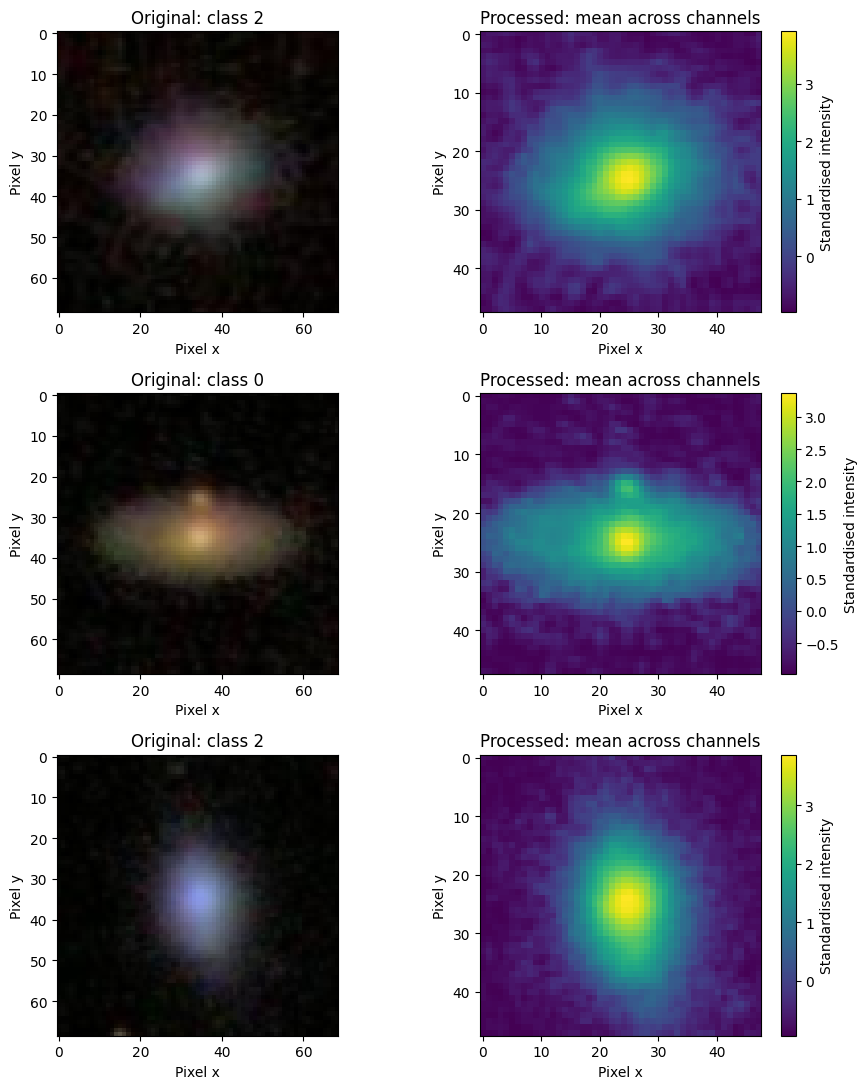

In [36]:
# 2.3（b,c）

CROP_START = 10
CROP_END = 58

def crop_and_subtract(raw_images):
    # Crop and subtract the per-image, per-channel sky median
    raw = np.asarray(raw_images)

    border = raw[:, border_mask, :].astype(np.float32)
    background = np.median(border, axis=1)

    cropped = raw[
        :, CROP_START:CROP_END, CROP_START:CROP_END, :
    ].astype(np.float32)

    return cropped - background[:, None, None, :]


# Fit normalisation statistics on the training set only.
channel_sum = np.zeros(3, dtype=np.float64)
channel_sum_sq = np.zeros(3, dtype=np.float64)
pixel_count = 0

for start in range(0, len(train_idx), 256):
    batch_indices = train_idx[start:start + 256]
    batch = crop_and_subtract(images[batch_indices]).astype(np.float64)

    channel_sum += batch.sum(axis=(0, 1, 2))
    channel_sum_sq += (batch**2).sum(axis=(0, 1, 2))
    pixel_count += batch.shape[0] * 48 * 48

train_mean = channel_sum / pixel_count
train_std = np.sqrt(
    np.maximum(channel_sum_sq / pixel_count - train_mean**2, 0)
)

assert np.all(train_std > 0)

def preprocess(raw_images):
    # Common preprocessing for all models; returns N × 3 × 48 × 48
    cropped = crop_and_subtract(raw_images)

    standardised = (
        cropped - train_mean[None, None, None, :]
    ) / train_std[None, None, None, :]

    return standardised.transpose(0, 3, 1, 2).astype(np.float32)


np.savez(
    folder / "preprocessing_stats.npz",
    mean=train_mean,
    std=train_std,
    crop_start=CROP_START,
    crop_end=CROP_END
)

print("Training means before standardisation:", train_mean)
print("Training standard deviations before standardisation:", train_std)
print("Preprocessed example shape:", preprocess(images[train_idx[:2]]).shape)

processed_sum = np.zeros(3, dtype=np.float64)
processed_sum_sq = np.zeros(3, dtype=np.float64)
processed_count = 0

for start in range(0, len(train_idx), 256):
    batch_indices = train_idx[start:start + 256]
    batch = preprocess(images[batch_indices]).astype(np.float64)

    processed_sum += batch.sum(axis=(0, 2, 3))
    processed_sum_sq += (batch**2).sum(axis=(0, 2, 3))
    processed_count += batch.shape[0] * 48 * 48

processed_mean = processed_sum / processed_count
processed_std = np.sqrt(np.maximum(
    processed_sum_sq / processed_count - processed_mean**2, 0
))

print("Processed training mean:", processed_mean)
print("Processed training std:", processed_std)

example_idx = train_idx[:3]
examples = preprocess(images[example_idx])

fig, axes = plt.subplots(3, 2, figsize=(9, 11))

for j, idx in enumerate(example_idx):
    axes[j, 0].imshow(images[idx])
    axes[j, 0].set_title(f"Original: class {labels[idx]}")

    display_map = examples[j].mean(axis=0)
    im = axes[j, 1].imshow(display_map, cmap="viridis")
    axes[j, 1].set_title("Processed: mean across channels")
    fig.colorbar(im, ax=axes[j, 1], label="Standardised intensity")

    for ax in axes[j]:
        ax.set_xlabel("Pixel x")
        ax.set_ylabel("Pixel y")

plt.tight_layout()
plt.savefig(folder / "preprocessing_examples.png",
            dpi=200, bbox_inches="tight")
plt.show()



Normalisation: Images are converted to floating point, background-subtracted, cropped, and standardised separately in each channel using training-set statistics. The same fixed statistics are applied to validation and test images. Using full-dataset statistics would leak information from the held-out sets into preprocessing.
Dividing each image by its brightest pixel removes its overall intensity scale and makes normalisation sensitive to bright contaminants or clipped pixels. Overall intensity may contain useful information about feature visibility, although apparent brightness also depends on distance and image processing. I therefore preserve between-image intensity differences using training-set standardisation.

Background subtraction: I subtract the per-image, per-channel border median to reduce additive sky offsets while retaining negative residuals. The median is relatively robust to isolated bright pixels, but extended galaxy light or substantial border contamination may bias the estimate.

In [37]:
# 2.3（d）

import torch
import torch.nn as nn

train_counts = np.bincount(labels[train_idx], minlength=10)
class_weights = len(train_idx) / (10 * train_counts)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32)
)

print(pd.DataFrame({
    "Class": np.arange(10),
    "Training count": train_counts,
    "Loss weight": class_weights
}).to_string(index=False))

 Class  Training count  Loss weight
     0            2423     0.629344
     1            4898     0.311331
     2            4404     0.346253
     3             244     6.249590
     4            1074     1.419832
     5              12   127.075000
     6             412     3.701214
     7             785     1.942548
     8             634     2.405205
     9             363     4.200826


I use class-weighted cross-entropy with $w_c=N_{\mathrm{train}}/(10N_c)$. Overall accuracy is dominated by common classes, so I also report balanced accuracy, the mean recall across all ten classes. Weighting increases the contribution of rare classes, but cannot compensate for the very limited number of class-5 examples.

In [38]:
# 2.4

| Transformation | Suitability and justification |
|---|---|
| Arbitrary-angle rotations | Preserve morphology labels because orientation on the sky does not determine the class. However, interpolation and cropping can alter fine features. |
| Rotations by multiples of \(90^\circ\) | Preserve labels and can be implemented without interpolation on square images. |
| Horizontal and vertical flips | Preserve these labels. They reverse spiral handedness, but the classes distinguish spiral tightness, not clockwise versus anticlockwise winding. |
| Small shifts | Preserve morphology if the galaxy remains inside the crop. Large shifts may remove important features. |
| Zoom | Modest changes may preserve the label, but resampling changes apparent size and feature resolution. Strong zooming may crop the galaxy or erase spiral structure. |
| Relative changes in \(g,r,i\) intensity | Are not a true symmetry: they change colour information associated with stellar populations and dust. Although the morphology label may remain unchanged, arbitrary changes can produce physically unrealistic colours. |
| Blurring | Changes observational resolution and can hide arms or bulges. Mild blur may model seeing variations, but strong blur can make the assigned class ambiguous. |

I would use random horizontal and vertical flips and rotations by multiples of \(90^\circ\), optionally combined with small shifts that retain the galaxy. These transformations preserve the relevant morphology while introducing few image-processing artefacts. I would avoid arbitrary colour changes, strong zooming, and strong blurring.

In [39]:
# 3.1

import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

assert torch.cuda.is_available(), "Please enable a GPU in Colab."

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

results_dir = folder / "part3"
results_dir.mkdir(exist_ok=True)

# Preprocess in batches to limit temporary memory usage.
def build_tensor(indices):
    output = np.empty((len(indices), 3, 48, 48), dtype=np.float32)

    for start in range(0, len(indices), 256):
        ids = indices[start:start + 256]
        output[start:start + len(ids)] = preprocess(images[ids])

    return torch.from_numpy(output)

X_train = build_tensor(train_idx)
X_val = build_tensor(val_idx)

y_train = torch.tensor(labels[train_idx], dtype=torch.long)
y_val = torch.tensor(labels[val_idx], dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

# Training-set class weights, identical for every model.
train_counts = np.bincount(labels[train_idx], minlength=10)
weights = torch.tensor(
    len(train_idx) / (10 * train_counts),
    dtype=torch.float32,
    device=device
)

print("Training tensor:", X_train.shape)
print("Validation tensor:", X_val.shape)


GPU: Tesla T4
Training tensor: torch.Size([15249, 3, 48, 48])
Validation tensor: torch.Size([3268, 3, 48, 48])


In [40]:
def make_model(name):
    if name == "CNN":
        return nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(6 * 6 * 64, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 10)
        )

    if name == "FCNN-matched":
        return nn.Sequential(
            nn.Flatten(),
            nn.Linear(48 * 48 * 3, 24),
            nn.ReLU(),
            nn.Linear(24, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 10)
        )

    if name == "FCNN-large":
        return nn.Sequential(
            nn.Flatten(),
            nn.Linear(48 * 48 * 3, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    raise ValueError(name)


expected_counts = {
    "CNN": 171754,
    "FCNN-matched": 168162,
    "FCNN-large": 1803914
}

for name, expected in expected_counts.items():
    model = make_model(name)
    count = sum(p.numel() for p in model.parameters())
    print(name, count)
    assert count == expected

del model


CNN 171754
FCNN-matched 168162
FCNN-large 1803914


In [41]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    loss_sum = 0.0
    weight_sum = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(xb)

            # weighted cross-entropy, summed over this batch
            numerator = nn.functional.cross_entropy(
                logits, yb, weight=weights, reduction="sum"
            )
            denominator = weights[yb].sum()
            loss = numerator / denominator

            if training:
                loss.backward()
                optimizer.step()

            loss_sum += numerator.detach().item()
            weight_sum += denominator.item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)

    return loss_sum / weight_sum, correct / total


def train_one(name, seed):
    set_seed(seed)

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=128,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=128,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    model = make_model(name).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    history = []
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    waiting = 0
    cumulative_seconds = 0.0

    # initialise CUDA operations before starting the epoch clock
    model.eval()
    with torch.no_grad():
        model(X_train[:2].to(device))
    torch.cuda.synchronize()

    for epoch in range(1, 51):
        torch.cuda.synchronize()
        start = time.perf_counter()

        train_loss, train_acc = run_epoch(
            model, train_loader, optimizer
        )
        val_loss, val_acc = run_epoch(model, val_loader)

        torch.cuda.synchronize()
        epoch_seconds = time.perf_counter() - start
        cumulative_seconds += epoch_seconds

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_acc,
            "val_accuracy": val_acc,
            "epoch_seconds": epoch_seconds,
            "cumulative_seconds": cumulative_seconds
        })

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            waiting = 0

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            torch.save(
                best_state,
                results_dir / f"{name}_seed{seed}_best.pt"
            )
        else:
            waiting += 1

        # save progress after each epoch
        pd.DataFrame(history).to_csv(
            results_dir / f"{name}_seed{seed}_history.csv",
            index=False
        )

        print(
            f"{name} | seed {seed} | epoch {epoch:02d} | "
            f"train loss {train_loss:.4f} | "
            f"val loss {val_loss:.4f} | "
            f"val acc {val_acc:.3f} | "
            f"{epoch_seconds:.1f}s",
            flush=True
        )

        if waiting >= 5:
            break

    # restore the weights selected by validation loss
    model.load_state_dict(best_state)

    summary = {
        "model": name,
        "seed": seed,
        "parameters": expected_counts[name],
        "best_epoch": best_epoch,
        "epochs_run": len(history),
        "best_val_loss": best_loss,
        "best_val_accuracy": max(
            row["val_accuracy"] for row in history
        ),
        "mean_epoch_seconds": np.mean(
            [row["epoch_seconds"] for row in history]
        ),
        "total_epoch_seconds": cumulative_seconds,
        "gpu": torch.cuda.get_device_name(0)
    }

    del model, optimizer
    torch.cuda.empty_cache()

    return summary


# train three seeds for each reference model
seeds = [42, 43, 44]
run_summaries = []

for name in ["FCNN-matched", "FCNN-large", "CNN"]:
    for seed in seeds:
        summary = train_one(name, seed)
        run_summaries.append(summary)

        pd.DataFrame(run_summaries).to_csv(
            results_dir / "training_summary.csv",
            index=False
        )

print("\nTRAINING COMPLETE")
print(pd.DataFrame(run_summaries).to_string(index=False))



FCNN-matched | seed 42 | epoch 01 | train loss 2.2184 | val loss 1.8980 | val acc 0.260 | 0.5s
FCNN-matched | seed 42 | epoch 02 | train loss 1.8932 | val loss 1.6628 | val acc 0.293 | 0.5s
FCNN-matched | seed 42 | epoch 03 | train loss 1.7368 | val loss 1.5884 | val acc 0.351 | 0.5s
FCNN-matched | seed 42 | epoch 04 | train loss 1.6976 | val loss 1.5300 | val acc 0.396 | 0.5s
FCNN-matched | seed 42 | epoch 05 | train loss 1.6029 | val loss 1.4178 | val acc 0.462 | 0.5s
FCNN-matched | seed 42 | epoch 06 | train loss 1.5419 | val loss 1.3602 | val acc 0.474 | 0.5s
FCNN-matched | seed 42 | epoch 07 | train loss 1.4343 | val loss 1.3625 | val acc 0.455 | 0.5s
FCNN-matched | seed 42 | epoch 08 | train loss 1.3726 | val loss 1.3479 | val acc 0.467 | 0.5s
FCNN-matched | seed 42 | epoch 09 | train loss 1.3585 | val loss 1.2987 | val acc 0.484 | 0.5s
FCNN-matched | seed 42 | epoch 10 | train loss 1.3017 | val loss 1.2628 | val acc 0.513 | 0.5s
FCNN-matched | seed 42 | epoch 11 | train loss 1.3

Common target validation accuracy: 0.655753
       model  seed  test_accuracy  test_balanced_accuracy  best_epoch  mean_epoch_seconds  target_epoch  target_seconds
FCNN-matched    42       0.543146                0.488509          20            0.465569           NaN             NaN
FCNN-matched    43       0.382803                0.398829          20            0.468846           NaN             NaN
FCNN-matched    44       0.626377                0.506978          21            0.467952          26.0       12.166749
  FCNN-large    42       0.644431                0.563563          19            0.572077          18.0        9.342058
  FCNN-large    43       0.629743                0.499459           7            0.525675           NaN             NaN
  FCNN-large    44       0.639841                0.558578          14            0.510639          19.0        9.702138
         CNN    42       0.643513                0.601215          14            0.983389          17.0       16.694

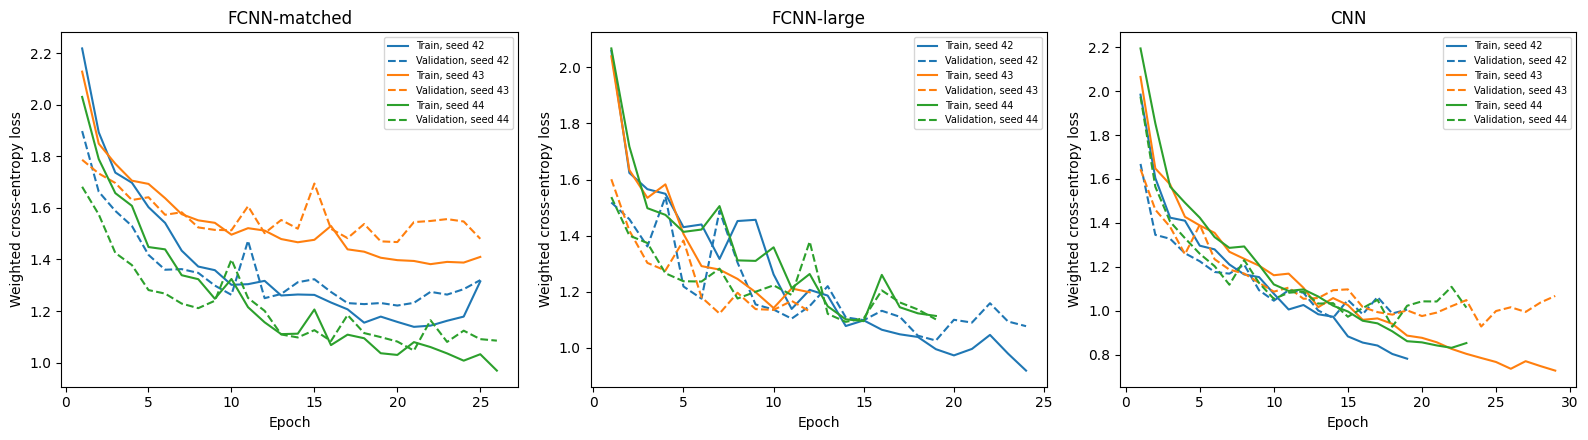

In [42]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)

# read saved training results.
summary_df = pd.read_csv(results_dir / "training_summary.csv")

target_accuracy = summary_df.loc[
    summary_df["model"] == "FCNN-matched",
    "best_val_accuracy"
].max()

print(f"Common target validation accuracy: {target_accuracy:.6f}")

# first final evaluation of the test images
X_test = build_tensor(test_idx)
y_test = torch.tensor(labels[test_idx], dtype=torch.long)

test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=128,
    shuffle=False,
    pin_memory=True
)

def predict_probabilities(model, loader):
    model.eval()
    probabilities = []

    with torch.no_grad():
        for xb, _ in loader:
            logits = model(xb.to(device))
            probabilities.append(
                torch.softmax(logits, dim=1).cpu().numpy()
            )

    return np.concatenate(probabilities)


evaluation_rows = []
test_probabilities = {}

for _, row in summary_df.iterrows():
    name = row["model"]
    seed = int(row["seed"])

    model = make_model(name).to(device)
    state = torch.load(
        results_dir / f"{name}_seed{seed}_best.pt",
        map_location="cpu",
        weights_only=True
    )
    model.load_state_dict(state)

    probabilities = predict_probabilities(model, test_loader)
    predictions = probabilities.argmax(axis=1)

    test_probabilities[(name, seed)] = probabilities

    history = pd.read_csv(
        results_dir / f"{name}_seed{seed}_history.csv"
    )

    reached = history[
        history["val_accuracy"] >= target_accuracy - 1e-12
    ]

    if len(reached):
        first = reached.iloc[0]
        target_epoch = int(first["epoch"])
        target_seconds = float(first["cumulative_seconds"])
    else:
        target_epoch = np.nan
        target_seconds = np.nan

    result = row.to_dict()
    result.update({
        "test_accuracy": accuracy_score(y_test.numpy(), predictions),
        "test_balanced_accuracy": balanced_accuracy_score(
            y_test.numpy(), predictions
        ),
        "target_epoch": target_epoch,
        "target_seconds": target_seconds
    })
    evaluation_rows.append(result)

    np.save(
        results_dir / f"{name}_seed{seed}_test_probabilities.npy",
        probabilities
    )

    del model
    torch.cuda.empty_cache()

evaluation_df = pd.DataFrame(evaluation_rows)
evaluation_df.to_csv(results_dir / "baseline_evaluation.csv", index=False)

print(evaluation_df[[
    "model", "seed", "test_accuracy", "test_balanced_accuracy",
    "best_epoch", "mean_epoch_seconds", "target_epoch", "target_seconds"
]].to_string(index=False))

# Sample standard deviation across the three seeds
metrics = [
    "test_accuracy", "test_balanced_accuracy",
    "parameters", "mean_epoch_seconds", "best_epoch"
]

aggregate = evaluation_df.groupby("model")[metrics].agg(["mean", "std"])
aggregate.to_csv(results_dir / "baseline_mean_std.csv")

print("\nMEAN AND SAMPLE STANDARD DEVIATION")
print(aggregate.to_string())

print("\nTARGET REACHED")
for name, group in evaluation_df.groupby("model"):
    successful = group.dropna(subset=["target_seconds"])
    print(f"{name}: {len(successful)}/3 seeds reached the target")

    if len(successful):
        print(
            "  Epochs:",
            successful["target_epoch"].mean(),
            "±", successful["target_epoch"].std()
        )
        print(
            "  Seconds:",
            successful["target_seconds"].mean(),
            "±", successful["target_seconds"].std()
        )

# Save the target definition
pd.DataFrame({
    "target_validation_accuracy": [target_accuracy],
    "definition": ["Maximum validation accuracy across FCNN-matched seeds"]
}).to_csv(results_dir / "common_target.csv", index=False)

model_names = ["FCNN-matched", "FCNN-large", "CNN"]
seed_colors = {42: "tab:blue", 43: "tab:orange", 44: "tab:green"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, name in zip(axes, model_names):
    for seed in seeds:
        history = pd.read_csv(
            results_dir / f"{name}_seed{seed}_history.csv"
        )

        ax.plot(
            history["epoch"], history["train_loss"],
            color=seed_colors[seed],
            label=f"Train, seed {seed}"
        )
        ax.plot(
            history["epoch"], history["val_loss"],
            color=seed_colors[seed], linestyle="--",
            label=f"Validation, seed {seed}"
        )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weighted cross-entropy loss")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig(results_dir / "baseline_loss_curves.png",
            dpi=200, bbox_inches="tight")
plt.show()


Best seeds selected by validation loss: {'CNN': 44, 'FCNN-large': 42, 'FCNN-matched': 44}


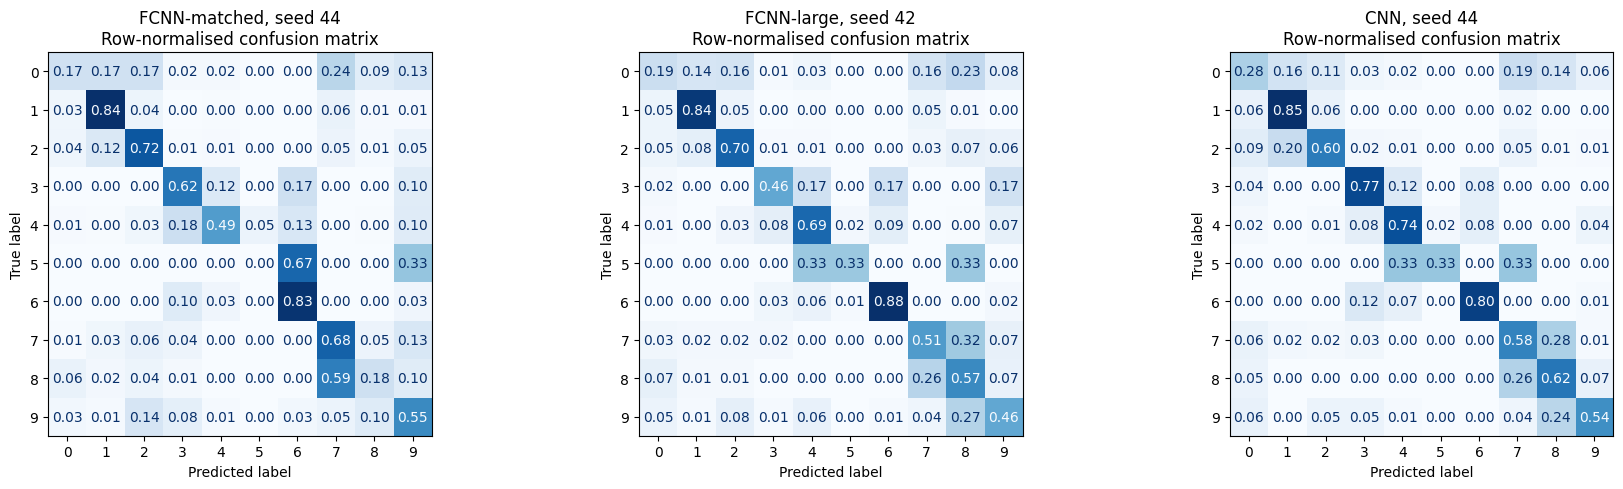

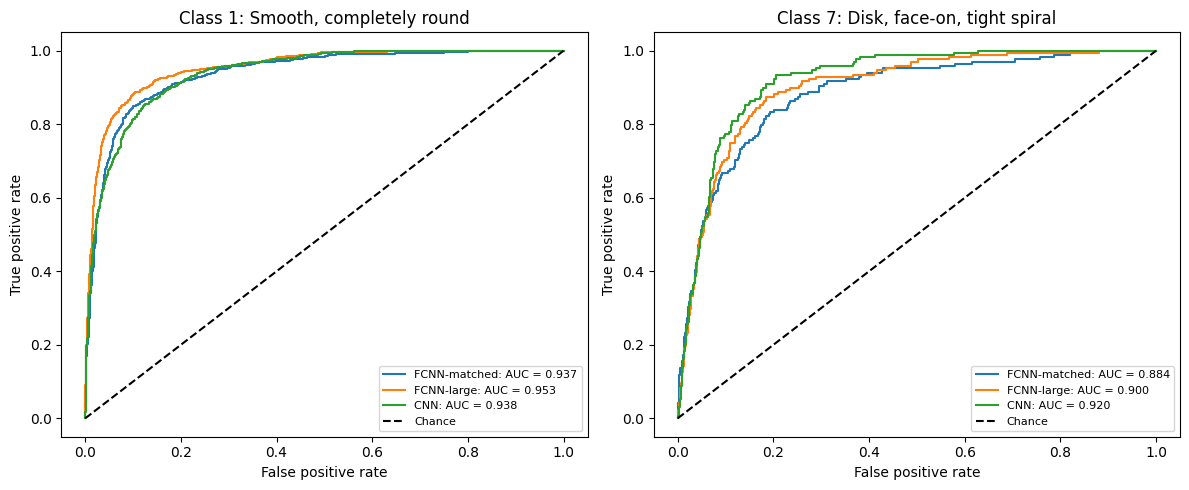

In [43]:
# Select each model's seed using validation loss only.
best_seeds = {
    name: int(
        group.loc[group["best_val_loss"].idxmin(), "seed"]
    )
    for name, group in summary_df.groupby("model")
}
print("Best seeds selected by validation loss:", best_seeds)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, model_names):
    seed = best_seeds[name]
    predictions = test_probabilities[(name, seed)].argmax(axis=1)

    # Row normalisation makes rare-class recall visible.
    cm = confusion_matrix(
        y_test.numpy(), predictions,
        labels=np.arange(10), normalize="true"
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=np.arange(10)
    )
    display_cm.plot(
        ax=ax, cmap="Blues",
        values_format=".2f", colorbar=False
    )
    ax.set_title(f"{name}, seed {seed}\nRow-normalised confusion matrix")

plt.tight_layout()
plt.savefig(results_dir / "baseline_confusion_matrices.png",
            dpi=200, bbox_inches="tight")
plt.show()

# One-vs-rest ROC curves.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, c in zip(axes, [1, 7]):
    binary_labels = (y_test.numpy() == c).astype(int)

    for name in model_names:
        seed = best_seeds[name]
        scores = test_probabilities[(name, seed)][:, c]
        fpr, tpr, _ = roc_curve(binary_labels, scores)

        ax.plot(
            fpr, tpr,
            label=f"{name}: AUC = {auc(fpr, tpr):.3f}"
        )

    ax.plot([0, 1], [0, 1], "k--", label="Chance")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"Class {c}: {class_names[c]}")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(results_dir / "baseline_roc_curves.png",
            dpi=200, bbox_inches="tight")
plt.show()


In [44]:
# Baseline results

All uncertainties below are sample standard deviations over three random seeds. Accuracy uncertainties are expressed in percentage points.

| Model | Test accuracy | Balanced accuracy | Parameters | Time per epoch (s) | Selected epoch |
|---|---:|---:|---:|---:|---:|
| FCNN-matched | \(51.74\pm12.38\%\) | \(46.48\pm5.79\%\) | 168,162 | \(0.539\pm0.042\) | \(20.33\pm0.58\) |
| FCNN-large | \(63.80\pm0.75\%\) | \(54.05\pm3.57\%\) | 1,803,914 | \(0.562\pm0.014\) | \(13.33\pm6.03\) |
| CNN | \(65.01\pm0.90\%\) | \(60.81\pm0.60\%\) | 171,754 | \(1.007\pm0.005\) | \(18.67\pm5.03\) |

The CNN achieves the highest mean test accuracy and balanced accuracy. Compared with FCNN-matched, it improves accuracy by 13.27 percentage points with a similar parameter count. FCNN-large substantially improves on FCNN-matched, but uses approximately 10.5 times as many parameters as the CNN and still has lower mean balanced accuracy. FCNN-matched is particularly sensitive to the random seed.
The CNN takes approximately 1.87 times as long per epoch as FCNN-matched on the Tesla T4. This measured runtime ratio is much smaller than the MAC ratio in T6, illustrating that arithmetic counts do not directly determine GPU runtime.

In [45]:
# Time to a common validation target

The target validation accuracy is \(65.5753\%\), the highest value reached by FCNN-matched across its three runs.

| Model | Seeds reaching target | Epochs to target | Time to target (s) |
|---|---:|---:|---:|
| FCNN-matched | 1/3 | 26 | 15.26 |
| FCNN-large | 2/3 | \(18.50\pm0.71\) | \(10.48\pm0.13\) |
| CNN | 3/3 | \(16.33\pm5.03\) | \(16.45\pm5.03\) |

Target-reaching statistics include successful runs only. No standard deviation can be estimated for FCNN-matched because only one run reaches the target. The CNN reaches the target in every run and requires fewer epochs on average, whereas FCNN-large reaches it in less wall-clock time among successful runs. Thus, the CNN is more reliable at reaching this target, but is not the fastest in elapsed time.

In [46]:
for name in model_names:
    seed = best_seeds[name]
    pred = test_probabilities[(name, seed)].argmax(axis=1)

    counts = confusion_matrix(
        y_test.numpy(), pred, labels=np.arange(10)
    )
    rates = counts / counts.sum(axis=1, keepdims=True)

    rows = []
    for true_class in range(10):
        for predicted_class in range(10):
            if true_class != predicted_class and counts[
                true_class, predicted_class
            ] > 0:
                rows.append({
                    "True class": true_class,
                    "Predicted class": predicted_class,
                    "Count": counts[true_class, predicted_class],
                    "Within-class error fraction":
                        rates[true_class, predicted_class]
                })

    top_errors = pd.DataFrame(rows).sort_values(
        "Within-class error fraction", ascending=False
    ).head(5)

    print(f"\n{name}, seed {seed}")
    print(top_errors.to_string(index=False))



FCNN-matched, seed 44
 True class  Predicted class  Count  Within-class error fraction
          5                6      2                     0.666667
          8                7     80                     0.588235
          5                9      1                     0.333333
          0                7    125                     0.240848
          4                3     42                     0.182609

FCNN-large, seed 42
 True class  Predicted class  Count  Within-class error fraction
          5                8      1                     0.333333
          5                4      1                     0.333333
          7                8     54                     0.321429
          9                8     21                     0.269231
          8                7     35                     0.257353

CNN, seed 44
 True class  Predicted class  Count  Within-class error fraction
          5                4      1                     0.333333
          5                7    

In [47]:
# Confusion analysis

The results agree with the expected ambiguity between spiral classes. For FCNN-matched, 58.8% of class-8 images are classified as class 7, and 24.1% of class-0 images are classified as class 7. These errors are consistent with difficulty distinguishing medium from tightly wound spirals and identifying weak spiral structure.
FCNN-large and the CNN also confuse classes 7, 8, and 9. For the CNN, 28.0% of class-7 images are predicted as class 8, 26.5% of class-8 images as class 7, and 24.4% of class-9 images as class 8. These classes differ by spiral-arm winding, which may be ambiguous at limited resolution. Such errors are consistent with morphological similarity, but do not by themselves establish label noise.
Class-5 results are highly uncertain because the test set contains only three examples; each error changes its recall by 33.3 percentage points.

Completed displacement d = 0
Completed displacement d = 2
Completed displacement d = 4
Completed displacement d = 6
Completed displacement d = 8

SHIFT RESULTS
                accuracy           balanced_accuracy          
                    mean       std              mean       std
model        d                                                
CNN          0  0.650143  0.008965          0.608114  0.006005
             2  0.633007  0.010011          0.568275  0.017978
             4  0.553550  0.019932          0.505645  0.015556
             6  0.420441  0.012418          0.419778  0.025845
             8  0.320481  0.017791          0.342057  0.019436
FCNN-large   0  0.638005  0.007514          0.540533  0.035658
             2  0.606181  0.003238          0.503852  0.024517
             4  0.427479  0.041069          0.370711  0.016101
             6  0.184007  0.048445          0.237116  0.019799
             8  0.099245  0.020338          0.188832  0.015143
FCNN-matched 0  0.517

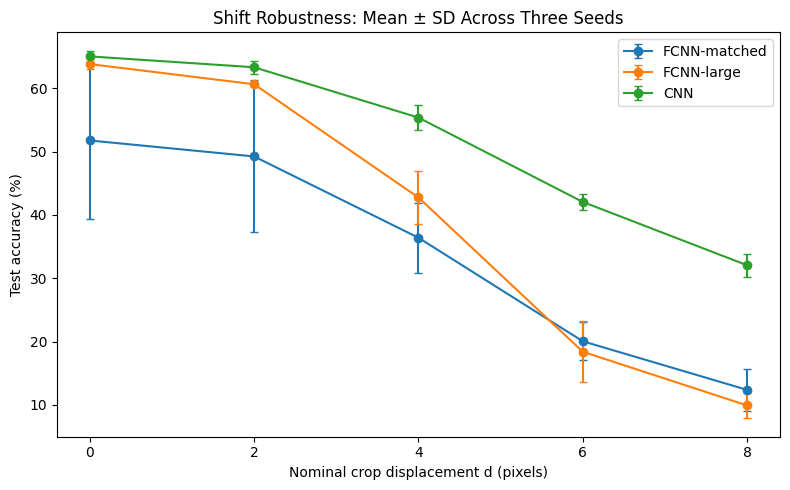

In [48]:
# 3.2

# Fix one random direction per test image, shared across all models.
shift_rng = np.random.default_rng(2026)
angles = shift_rng.uniform(0, 2 * np.pi, len(test_idx))
distances = [0, 2, 4, 6, 8]

def make_shifted_test_tensor(d):
    dx = np.rint(d * np.cos(angles)).astype(int)
    dy = np.rint(d * np.sin(angles)).astype(int)

    output = np.empty(
        (len(test_idx), 3, 48, 48), dtype=np.float32
    )

    for start in range(0, len(test_idx), 256):
        ids = test_idx[start:start + 256]
        raw = images[ids]

        # Same background estimator as the baseline.
        border = raw[:, border_mask, :].astype(np.float32)
        background = np.median(border, axis=1)

        cropped = np.empty(
            (len(ids), 48, 48, 3), dtype=np.float32
        )

        for j in range(len(ids)):
            position = start + j
            y0 = 10 + dy[position]
            x0 = 10 + dx[position]

            cropped[j] = raw[j, y0:y0 + 48, x0:x0 + 48, :]

        processed = (
            cropped - background[:, None, None, :]
            - train_mean[None, None, None, :]
        ) / train_std[None, None, None, :]

        output[start:start + len(ids)] = processed.transpose(
            0, 3, 1, 2
        )

    return torch.from_numpy(output), dx, dy


# Load all nine saved baseline models once.
shift_models = {}

for name in model_names:
    for seed in seeds:
        model = make_model(name).to(device)
        model.load_state_dict(torch.load(
            results_dir / f"{name}_seed{seed}_best.pt",
            map_location="cpu",
            weights_only=True
        ))
        model.eval()
        shift_models[(name, seed)] = model

shift_rows = []

for d in distances:
    shifted_X, dx, dy = make_shifted_test_tensor(d)

    if d == 0:
        assert torch.allclose(shifted_X, X_test)

    np.savez(
        results_dir / f"test_offsets_d{d}.npz",
        test_idx=test_idx, dx=dx, dy=dy
    )

    shifted_loader = DataLoader(
        TensorDataset(shifted_X, y_test),
        batch_size=128,
        shuffle=False,
        pin_memory=True
    )

    for (name, seed), model in shift_models.items():
        probabilities = predict_probabilities(model, shifted_loader)
        predictions = probabilities.argmax(axis=1)

        shift_rows.append({
            "model": name,
            "seed": seed,
            "d": d,
            "accuracy": accuracy_score(y_test.numpy(), predictions),
            "balanced_accuracy": balanced_accuracy_score(
                y_test.numpy(), predictions
            )
        })

    print(f"Completed displacement d = {d}", flush=True)

shift_df = pd.DataFrame(shift_rows)
shift_df.to_csv(results_dir / "shift_results.csv", index=False)

shift_summary = shift_df.groupby(
    ["model", "d"]
)[["accuracy", "balanced_accuracy"]].agg(["mean", "std"])

shift_summary.to_csv(results_dir / "shift_mean_std.csv")

print("\nSHIFT RESULTS")
print(shift_summary.to_string())

fig, ax = plt.subplots(figsize=(8, 5))

for name in model_names:
    group = shift_df[shift_df["model"] == name]
    stats = group.groupby("d")["accuracy"].agg(["mean", "std"])

    ax.errorbar(
        stats.index,
        100 * stats["mean"],
        yerr=100 * stats["std"],
        marker="o", capsize=3, label=name
    )

ax.set_xlabel("Nominal crop displacement d (pixels)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Shift Robustness: Mean ± SD Across Three Seeds")
ax.set_xticks(distances)
ax.legend()

plt.tight_layout()
plt.savefig(results_dir / "shift_accuracy.png",
            dpi=200, bbox_inches="tight")
plt.show()

del shift_models
torch.cuda.empty_cache()



| Displacement (pixels) | FCNN-matched accuracy | FCNN-large accuracy | CNN accuracy |
|---|---:|---:|---:|
| 0 | 51.74% | 63.80% | 65.01% |
| 2 | 49.22% | 60.62% | 63.30% |
| 4 | 36.39% | 42.75% | 55.35% |
| 6 | 20.05% | 18.40% | 42.04% |
| 8 | 12.38% | 9.92% | 32.05% |

Shift robustness. Accuracy decreases with displacement for all three models. At \(d=8\), the CNN loses 32.97 percentage points, compared with 39.36 for FCNN-matched and 53.88 for FCNN-large. The CNN also retains higher balanced accuracy at this displacement: 34.21%, compared with approximately 18.7%–18.9% for the FCNNs.
These results support T4: shared local filters and pooling improve shift tolerance. However, the CNN is not translation invariant. Strided pooling and position-dependent dense layers remain sensitive to feature location, while displaced crops may remove peripheral information. FCNN-large’s greater capacity does not guarantee greater shift robustness.

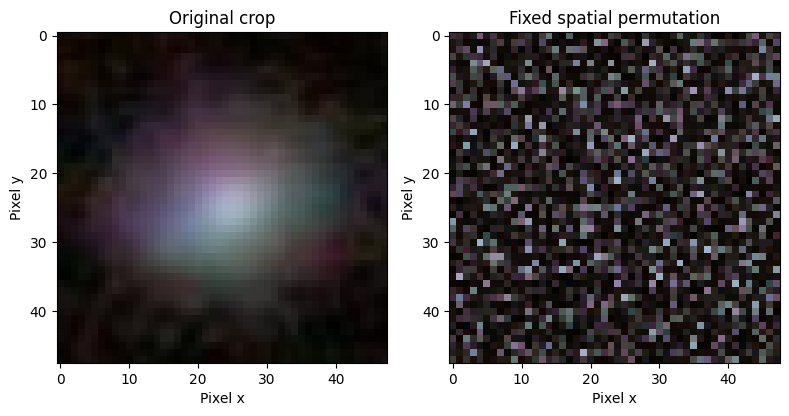

In [49]:
# 3.3

# One fixed spatial permutation for all images and all seeds.
permutation = np.random.default_rng(2026).permutation(48 * 48)
perm_tensor = torch.tensor(permutation, dtype=torch.long)

def scramble_tensor(x):
    # N × C × H × W -> N × C × spatial positions
    return x.flatten(start_dim=2)[:, :, perm_tensor].reshape(
        -1, 3, 48, 48
    ).contiguous()

X_train_scrambled = scramble_tensor(X_train)
X_val_scrambled = scramble_tensor(X_val)
X_test_scrambled = scramble_tensor(X_test)

scramble_dir = folder / "part3_scrambled"
scramble_dir.mkdir(exist_ok=True)
np.save(scramble_dir / "pixel_permutation.npy", permutation)

# Display one image before and after the same permutation.
raw_crop = images[train_idx[0], 10:58, 10:58, :]
scrambled_crop = raw_crop.reshape(-1, 3)[permutation].reshape(48, 48, 3)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, img, title in zip(
    axes,
    [raw_crop, scrambled_crop],
    ["Original crop", "Fixed spatial permutation"]
):
    ax.imshow(img)
    ax.set_title(title)
    ax.set_xlabel("Pixel x")
    ax.set_ylabel("Pixel y")

plt.tight_layout()
plt.savefig(scramble_dir / "scrambled_example.png",
            dpi=200, bbox_inches="tight")
plt.show()


In [50]:
# keep references to the baseline configuration
baseline_results_dir = results_dir
baseline_train_dataset = train_dataset
baseline_val_dataset = val_dataset

scrambled_rows = []

try:
    results_dir = scramble_dir

    train_dataset = TensorDataset(X_train_scrambled, y_train)
    val_dataset = TensorDataset(X_val_scrambled, y_val)

    scrambled_test_loader = DataLoader(
        TensorDataset(X_test_scrambled, y_test),
        batch_size=128,
        shuffle=False,
        pin_memory=True
    )

    for name in ["FCNN-matched", "CNN"]:
        for seed in seeds:
            # fresh model and optimizer for every run.
            result = train_one(name, seed)

            model = make_model(name).to(device)
            model.load_state_dict(torch.load(
                scramble_dir / f"{name}_seed{seed}_best.pt",
                map_location="cpu",
                weights_only=True
            ))

            probabilities = predict_probabilities(
                model, scrambled_test_loader
            )
            predictions = probabilities.argmax(axis=1)

            result["test_accuracy"] = accuracy_score(
                y_test.numpy(), predictions
            )
            result["test_balanced_accuracy"] = balanced_accuracy_score(
                y_test.numpy(), predictions
            )
            scrambled_rows.append(result)

            pd.DataFrame(scrambled_rows).to_csv(
                scramble_dir / "scrambled_evaluation.csv",
                index=False
            )

            del model
            torch.cuda.empty_cache()

finally:
    # restore baseline configuration even if a run fails
    results_dir = baseline_results_dir
    train_dataset = baseline_train_dataset
    val_dataset = baseline_val_dataset

scrambled_df = pd.DataFrame(scrambled_rows)

print("\nSCRAMBLED RESULTS")
print(scrambled_df[[
    "model", "seed", "test_accuracy",
    "test_balanced_accuracy", "best_epoch"
]].to_string(index=False))

# direct comparison against the original baseline
baseline_comparison = evaluation_df[
    evaluation_df["model"].isin(["FCNN-matched", "CNN"])
].copy()
baseline_comparison["input"] = "Original"

scrambled_comparison = scrambled_df.copy()
scrambled_comparison["input"] = "Scrambled"

comparison = pd.concat(
    [baseline_comparison, scrambled_comparison],
    ignore_index=True
)

comparison_summary = comparison.groupby(
    ["model", "input"]
)[["test_accuracy", "test_balanced_accuracy"]].agg(["mean", "std"])

comparison_summary.to_csv(
    scramble_dir / "original_vs_scrambled.csv"
)

print("\nORIGINAL VS SCRAMBLED")
print(comparison_summary.to_string())



FCNN-matched | seed 42 | epoch 01 | train loss 2.2111 | val loss 1.9731 | val acc 0.266 | 0.5s
FCNN-matched | seed 42 | epoch 02 | train loss 1.9468 | val loss 1.7073 | val acc 0.315 | 0.5s
FCNN-matched | seed 42 | epoch 03 | train loss 1.7795 | val loss 1.5296 | val acc 0.481 | 0.5s
FCNN-matched | seed 42 | epoch 04 | train loss 1.6840 | val loss 1.5163 | val acc 0.472 | 0.5s
FCNN-matched | seed 42 | epoch 05 | train loss 1.5576 | val loss 1.4007 | val acc 0.561 | 0.5s
FCNN-matched | seed 42 | epoch 06 | train loss 1.5132 | val loss 1.2911 | val acc 0.559 | 0.5s
FCNN-matched | seed 42 | epoch 07 | train loss 1.4033 | val loss 1.2833 | val acc 0.583 | 0.5s
FCNN-matched | seed 42 | epoch 08 | train loss 1.3464 | val loss 1.2827 | val acc 0.545 | 0.5s
FCNN-matched | seed 42 | epoch 09 | train loss 1.3472 | val loss 1.2023 | val acc 0.558 | 0.5s
FCNN-matched | seed 42 | epoch 10 | train loss 1.2213 | val loss 1.1537 | val acc 0.573 | 0.5s
FCNN-matched | seed 42 | epoch 11 | train loss 1.2

One fixed spatial permutation is applied to every image, preserving each pixel’s three channels. Both models are retrained from scratch using the baseline protocol and three random seeds.
The CNN’s mean accuracy decreases by 2.59 percentage points and its balanced accuracy decreases by 4.89 points. This supports the prediction that destroying spatial locality weakens its useful inductive bias. However, the decrease is smaller than predicted in T5.
Scrambling preserves all pixel values and is invertible. The CNN may still exploit intensity and colour distributions, while its dense layers can combine information across the scrambled feature maps. These are possible explanations for its retained performance; this experiment alone does not identify which information it uses.
FCNN-matched’s mean accuracy increases by 4.94 percentage points. A fixed permutation does not change its representational capacity, as shown in T5, but finite training and early stopping can produce different outcomes. Given the substantial seed variability and only three runs, this increase does not establish a systematic benefit from scrambling.
Overall, the results support the FCNN’s ability to accommodate a fixed input permutation and show that spatial locality benefits the CNN, although it is not essential for all of its classification performance.

In [51]:
# B3. Augmentation

class AugmentedGalaxyDataset(torch.utils.data.Dataset):
    def __init__(self, images, indices):
        self.images = images
        self.indices = indices

        # background is always estimated from the original image border
        self.background = np.empty((len(indices), 3), dtype=np.float32)

        for start in range(0, len(indices), 256):
            ids = indices[start:start + 256]
            border = images[ids][:, border_mask, :].astype(np.float32)
            self.background[start:start + len(ids)] = np.median(
                border, axis=1
            )

        self.mean = torch.tensor(train_mean, dtype=torch.float32)[:, None, None]
        self.std = torch.tensor(train_std, dtype=torch.float32)[:, None, None]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = self.indices[i]

        # Random shifted crop from the full image
        dx = int(torch.randint(-4, 5, ()).item())
        dy = int(torch.randint(-4, 5, ()).item())

        crop = self.images[
            idx, 10 + dy:58 + dy, 10 + dx:58 + dx, :
        ].astype(np.float32)

        crop -= self.background[i]
        x = torch.from_numpy(crop.transpose(2, 0, 1).copy())

        if torch.rand(()).item() < 0.5:
            x = torch.flip(x, dims=[2])

        if torch.rand(()).item() < 0.5:
            x = torch.flip(x, dims=[1])

        k = int(torch.randint(0, 4, ()).item())
        x = torch.rot90(x, k, dims=[1, 2])

        x = (x - self.mean) / self.std
        y = int(labels[idx])

        return x.contiguous(), y


augmented_dataset = AugmentedGalaxyDataset(images, train_idx)
aug_dir = folder / "part3_augmented"
aug_dir.mkdir(exist_ok=True)

print("Augmented training images:", len(augmented_dataset))


Augmented training images: 15249


In [52]:
baseline_results_dir = results_dir
baseline_train_dataset = train_dataset
baseline_val_dataset = val_dataset

augmented_rows = []
augmented_shift_rows = []

try:
    results_dir = aug_dir
    train_dataset = augmented_dataset
    val_dataset = baseline_val_dataset

    for name in ["FCNN-matched", "CNN"]:
        for seed in seeds:
            result = train_one(name, seed)

            model = make_model(name).to(device)
            model.load_state_dict(torch.load(
                aug_dir / f"{name}_seed{seed}_best.pt",
                map_location="cpu",
                weights_only=True
            ))

            for d in distances:
                shifted_X, _, _ = make_shifted_test_tensor(d)

                loader = DataLoader(
                    TensorDataset(shifted_X, y_test),
                    batch_size=128,
                    shuffle=False,
                    pin_memory=True
                )

                probabilities = predict_probabilities(model, loader)
                predictions = probabilities.argmax(axis=1)

                acc = accuracy_score(y_test.numpy(), predictions)
                bal_acc = balanced_accuracy_score(
                    y_test.numpy(), predictions
                )

                augmented_shift_rows.append({
                    "model": name,
                    "seed": seed,
                    "d": d,
                    "accuracy": acc,
                    "balanced_accuracy": bal_acc
                })

                if d == 0:
                    result["test_accuracy"] = acc
                    result["test_balanced_accuracy"] = bal_acc

            # Measure the gap at the selected checkpoint.
            # Both sets are unaugmented and Dropout is disabled,
            # so the losses are directly comparable.
            clean_train_loader = DataLoader(
                baseline_train_dataset,
                batch_size=128,
                shuffle=False,
                pin_memory=True
            )
            clean_val_loader = DataLoader(
                baseline_val_dataset,
                batch_size=128,
                shuffle=False,
                pin_memory=True
            )

            train_loss, _ = run_epoch(model, clean_train_loader)
            val_loss, _ = run_epoch(model, clean_val_loader)

            result["clean_train_loss"] = train_loss
            result["clean_val_loss"] = val_loss
            result["loss_gap"] = val_loss - train_loss

            augmented_rows.append(result)

            pd.DataFrame(augmented_rows).to_csv(
                aug_dir / "augmented_evaluation.csv", index=False
            )
            pd.DataFrame(augmented_shift_rows).to_csv(
                aug_dir / "augmented_shift_results.csv", index=False
            )

            del model
            torch.cuda.empty_cache()

finally:
    results_dir = baseline_results_dir
    train_dataset = baseline_train_dataset
    val_dataset = baseline_val_dataset

augmented_df = pd.DataFrame(augmented_rows)
augmented_shift_df = pd.DataFrame(augmented_shift_rows)

print("\nAUGMENTED RESULTS")
print(augmented_df[[
    "model", "seed", "test_accuracy",
    "test_balanced_accuracy", "loss_gap", "best_epoch"
]].to_string(index=False))



FCNN-matched | seed 42 | epoch 01 | train loss 2.2480 | val loss 1.8926 | val acc 0.230 | 2.1s
FCNN-matched | seed 42 | epoch 02 | train loss 2.0277 | val loss 1.8648 | val acc 0.181 | 2.1s
FCNN-matched | seed 42 | epoch 03 | train loss 1.9601 | val loss 1.7854 | val acc 0.324 | 2.1s
FCNN-matched | seed 42 | epoch 04 | train loss 1.9035 | val loss 1.7057 | val acc 0.379 | 2.0s
FCNN-matched | seed 42 | epoch 05 | train loss 1.8133 | val loss 1.6689 | val acc 0.410 | 2.0s
FCNN-matched | seed 42 | epoch 06 | train loss 1.8267 | val loss 1.5785 | val acc 0.383 | 2.0s
FCNN-matched | seed 42 | epoch 07 | train loss 1.7037 | val loss 1.5492 | val acc 0.404 | 2.1s
FCNN-matched | seed 42 | epoch 08 | train loss 1.7197 | val loss 1.6442 | val acc 0.375 | 2.1s
FCNN-matched | seed 42 | epoch 09 | train loss 1.6680 | val loss 1.5807 | val acc 0.415 | 2.1s
FCNN-matched | seed 42 | epoch 10 | train loss 1.6243 | val loss 1.4571 | val acc 0.427 | 2.1s
FCNN-matched | seed 42 | epoch 11 | train loss 1.6


B3 COMPARISON
                       test_accuracy           test_balanced_accuracy            loss_gap          
                                mean       std                   mean       std      mean       std
model        condition                                                                             
CNN          Augmented      0.636373  0.058482               0.585467  0.026828 -0.018236  0.021414
             Baseline       0.650143  0.008965               0.608114  0.006005  0.244068  0.052196
FCNN-matched Augmented      0.533762  0.044544               0.441075  0.033798 -0.041818  0.007891
             Baseline       0.517442  0.123805               0.464772  0.057850  0.146806  0.028845


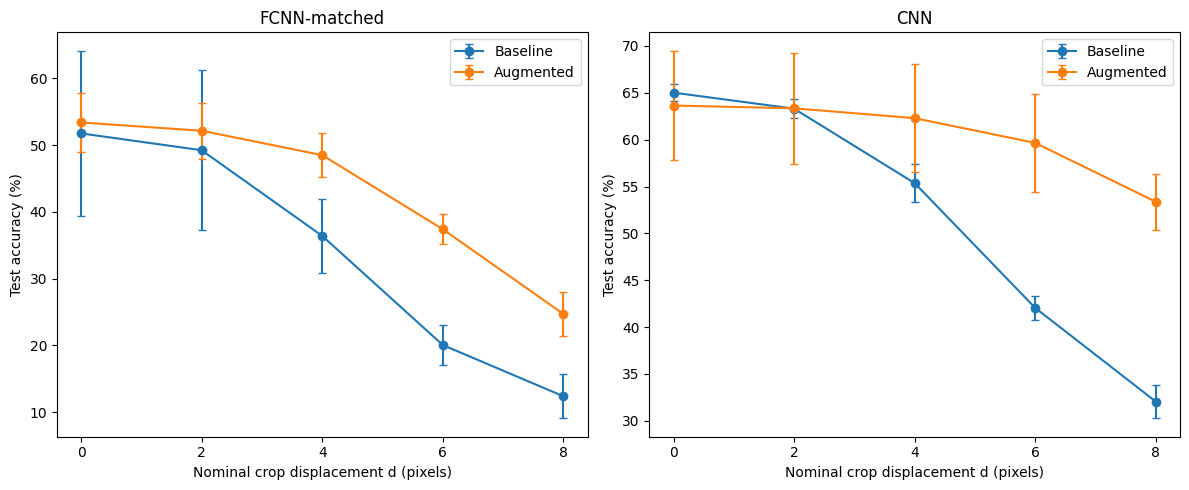


AUGMENTED SHIFT SUMMARY
                accuracy           balanced_accuracy          
                    mean       std              mean       std
model        d                                                
CNN          0  0.636373  0.058482          0.585467  0.026828
             2  0.633415  0.059408          0.583670  0.032936
             4  0.622909  0.057441          0.578003  0.032033
             6  0.596491  0.052056          0.553789  0.050583
             8  0.533660  0.030117          0.524791  0.043282
FCNN-matched 0  0.533762  0.044544          0.441075  0.033798
             2  0.521420  0.041606          0.431944  0.052958
             4  0.484904  0.032692          0.409221  0.047898
             6  0.373929  0.022538          0.357033  0.038989
             8  0.247042  0.032822          0.293803  0.024232


In [53]:
baseline_gap_rows = []

clean_train_loader = DataLoader(
    baseline_train_dataset,
    batch_size=128, shuffle=False, pin_memory=True
)
clean_val_loader = DataLoader(
    baseline_val_dataset,
    batch_size=128, shuffle=False, pin_memory=True
)

for name in ["FCNN-matched", "CNN"]:
    for seed in seeds:
        model = make_model(name).to(device)
        model.load_state_dict(torch.load(
            baseline_results_dir / f"{name}_seed{seed}_best.pt",
            map_location="cpu",
            weights_only=True
        ))

        train_loss, _ = run_epoch(model, clean_train_loader)
        val_loss, _ = run_epoch(model, clean_val_loader)

        baseline_gap_rows.append({
            "model": name,
            "seed": seed,
            "clean_train_loss": train_loss,
            "clean_val_loss": val_loss,
            "loss_gap": val_loss - train_loss
        })

        del model

torch.cuda.empty_cache()

baseline_b3 = evaluation_df[
    evaluation_df["model"].isin(["FCNN-matched", "CNN"])
].merge(pd.DataFrame(baseline_gap_rows), on=["model", "seed"])

baseline_b3["condition"] = "Baseline"
augmented_df["condition"] = "Augmented"

b3_comparison = pd.concat(
    [baseline_b3, augmented_df], ignore_index=True
)

b3_summary = b3_comparison.groupby(
    ["model", "condition"]
)[[
    "test_accuracy", "test_balanced_accuracy", "loss_gap"
]].agg(["mean", "std"])

b3_summary.to_csv(aug_dir / "b3_comparison.csv")

print("\nB3 COMPARISON")
print(b3_summary.to_string())

# compare baseline and augmented shift curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, ["FCNN-matched", "CNN"]):
    for frame, condition in [
        (shift_df, "Baseline"),
        (augmented_shift_df, "Augmented")
    ]:
        stats = frame[frame["model"] == name].groupby(
            "d"
        )["accuracy"].agg(["mean", "std"])

        ax.errorbar(
            stats.index,
            100 * stats["mean"],
            yerr=100 * stats["std"],
            marker="o", capsize=3, label=condition
        )

    ax.set_title(name)
    ax.set_xlabel("Nominal crop displacement d (pixels)")
    ax.set_ylabel("Test accuracy (%)")
    ax.set_xticks(distances)
    ax.legend()

plt.tight_layout()
plt.savefig(aug_dir / "augmentation_shift_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()

print("\nAUGMENTED SHIFT SUMMARY")
print(
    augmented_shift_df.groupby(["model", "d"])[
        ["accuracy", "balanced_accuracy"]
    ].agg(["mean", "std"]).to_string()
)


I retrain CNN and FCNN-matched with random horizontal and vertical flips, rotations by multiples of \(90^\circ\), and crop shifts of up to four pixels along each axis. All other training settings remain unchanged. Results are mean ± sample standard deviation over three seeds.

| Model | Training | Test accuracy | Balanced accuracy | Validation–training loss gap |
|---|---|---:|---:|---:|
| FCNN-matched | Baseline | \(51.74\pm12.38\%\) | \(46.48\pm5.79\%\) | \(0.147\pm0.029\) |
| FCNN-matched | Augmented | \(53.38\pm4.45\%\) | \(44.11\pm3.38\%\) | \(-0.042\pm0.008\) |
| CNN | Baseline | \(65.01\pm0.90\%\) | \(60.81\pm0.60\%\) | \(0.244\pm0.052\) |
| CNN | Augmented | \(63.64\pm5.85\%\) | \(58.55\pm2.68\%\) | \(-0.018\pm0.021\) |

The loss gaps are evaluated at the selected checkpoints using unaugmented training and validation images, with dropout disabled. Augmentation removes the positive generalisation gap for both models. However, a smaller gap does not necessarily imply better classification: balanced accuracy decreases for both models. Slightly negative gaps mean validation loss is lower than training loss, which can arise from differences between the finite datasets.

| Displacement | FCNN-matched baseline | FCNN-matched augmented | CNN baseline | CNN augmented |
|---|---:|---:|---:|---:|
| 0 | 51.74% | 53.38% | 65.01% | 63.64% |
| 2 | 49.22% | 52.14% | 63.30% | 63.34% |
| 4 | 36.39% | 48.49% | 55.35% | 62.29% |
| 6 | 20.05% | 37.39% | 42.04% | 59.65% |
| 8 | 12.38% | 24.70% | 32.05% | 53.37% |

Augmentation substantially improves robustness to shifts. At \(d=8\), accuracy increases by 21.32 percentage points for the CNN and 12.32 points for FCNN-matched. Balanced accuracy also improves, from 34.21% to 52.48% for the CNN and from 18.73% to 29.38% for FCNN-matched.

Thus, the CNN gains more in absolute accuracy at the largest tested displacement. A plausible explanation is that augmentation complements its shared local filters by exposing later layers to features at varying positions. The FCNN also learns greater shift tolerance, but lacks built-in spatial weight sharing. Because rotations, flips, and shifts were introduced together, their individual contributions cannot be separated.
On unshifted images, FCNN-matched gains only 1.63 accuracy points while the CNN loses 1.38 points; both lose balanced accuracy. With three seeds and substantial variability, these results do not establish an improvement in unshifted classification. The clearest benefit is increased shift robustness.

In [54]:
# 4（a）

Baseline results are mean ± sample standard deviation across three seeds. MACs refer to one forward pass per image.

| Model | Accuracy (%) | Balanced accuracy (%) | Parameters | MACs | Time/epoch (s) | Time to target (s) |
|---|---:|---:|---:|---:|---:|---:|
| FCNN-matched | \(51.74\pm12.38\) | \(46.48\pm5.79\) | 168,162 | 168,064 | \(0.539\pm0.042\) | 15.26 (1/3) |
| FCNN-large | \(63.80\pm0.75\) | \(54.05\pm3.57\) | 1,803,914 | 1,803,520 | \(0.562\pm0.014\) | \(10.48\pm0.13\) (2/3) |
| CNN | \(65.01\pm0.90\) | \(60.81\pm0.60\) | 171,754 | 6,451,840 | \(1.007\pm0.005\) | \(16.45\pm5.03\) (3/3) |

The target is 65.5753% validation accuracy; target times include successful runs only, with the number reaching it shown in parentheses. Timing includes training and validation on a Tesla T4, excluding checkpoint saving. The CNN has the highest mean accuracy and balanced accuracy, but takes longer per epoch. It reaches the target most reliably and in fewer epochs on average; FCNN-large reaches it fastest in elapsed time among successful runs.

In [55]:
# 4（b）

Spatial locality favours the CNN: scrambling reduces its balanced accuracy from 60.81% to 55.92%, although the modest decrease shows that useful information remains without intact neighbourhoods. Approximate translation symmetry also favours convolution and pooling: at an eight-pixel displacement, baseline CNN accuracy remains 32.05%, compared with 12.38% and 9.92% for the FCNNs. Augmentation raises the CNN’s shifted accuracy to 53.37%.

Hierarchical combinations of local features are suitable for describing arms and bulges. The CNN’s higher balanced accuracy with approximately the same parameter budget as FCNN-matched is consistent with this advantage, although these experiments do not isolate hierarchy from other architectural differences. Background noise and contamination complicate feature extraction; shared filters can learn reusable patterns, but no noise-injection experiment was performed to establish superior noise robustness directly.

In [56]:
# 4（c）

A 2D CNN would be inappropriate for a five-element \(u,g,r,i,z\) feature vector because it has no natural two-dimensional spatial structure. A 1D CNN could exploit wavelength ordering, but its weight sharing assumes that the same local pattern is useful across different band positions. The bands have distinct physical meanings and are not uniformly spaced in wavelength, so this assumption is weak. A small FCNN or another tabular classifier would be a more natural starting point.

In [57]:
# 4（d）

Accuracy is limited by finite resolution, background fluctuations, contamination, information lost through quantisation or clipping, class imbalance, and ambiguous labels. Confusion among spiral classes 7–9 is consistent with limited feature visibility or uncertain annotations, but does not prove label errors. Class 5 has only 12 training examples, making learning and evaluation particularly unreliable.
I would first improve the label and sample quality: review ambiguous classifications, retain vote probabilities where available, and obtain more rare-class examples. I would also validate contamination detection and background estimates. These data limitations warrant attention before simply increasing model size; FCNN-large already shows that substantially more parameters do not guarantee the best performance.